# E1: calibrated SVM probabilities

Use the selected 35-feature SVM from the 39-feature study and the selected
65-feature SVM from the 91-feature study. Keep the 91-feature SVM as a reference.

Original balanced accuracy from the comparison notebooks:

| SVM features | Validation | Test |
| --- | --- | --- |
| 35 | 95.04% | 94.60% |
| 65 | 96.44% | 96.24% |
| 91 | 96.22% | 96.11% |

Fit sigmoid calibration with five speaker-separated folds on training plus validation.
Keep saved feature columns fixed and fit the scaler inside each fold.
Save separate calibrated files and check scores against the originals.
Test clips stay out of fitting. **Run All includes test evaluation.**

Use Singapore (`1`) when `p_singapore >= 0.50`; otherwise Non-Singapore (`0`).
This is exploratory: feature selection used development labels, and test speakers
were used before. Sources and prompts differ between classes. High probability
does not detect unfamiliar audio.

In [1]:
from pathlib import Path
import hashlib
import json
from time import perf_counter

import joblib
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import balanced_accuracy_score, brier_score_loss, confusion_matrix, log_loss
from sklearn.model_selection import StratifiedGroupKFold
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
STUDY_DIR = PROJECT_ROOT / 'outputs/e1_feature_study_accent_30000'
RESULTS_DIR = STUDY_DIR / 'svm_calibrated_probability_testing'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_SEED = 42
CV_FOLDS = 5
THRESHOLD = 0.50  # Fixed threshold.
MODEL_PATHS = {
    35: 'results/svm_35.joblib',
    65: 'results_91/svm_65.joblib',
    91: 'results_91/svm_91.joblib',
}
COUNTS = tuple(MODEL_PATHS)


def file_hash(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True).encode()).hexdigest()


# Load the same clips and splits as both studies.
snapshot = pd.read_csv(STUDY_DIR / 'speaker_splits.csv', index_col='clip_id', keep_default_na=False,
    dtype={column: str for column in ['clip_id', 'speaker_group', 'split', 'source',
                                     'source_clip_id', 'speaker_id', 'accent_group']})
if snapshot.empty or not snapshot.index.is_unique or snapshot.isna().any().any():
    raise ValueError('Invalid saved split.')
if not set(snapshot['split']) <= {'train', 'validation', 'test'}:
    raise ValueError('Unexpected split name.')
if (snapshot.groupby('speaker_group')['split'].nunique() > 1).any():
    raise ValueError('Speaker overlap between splits.')
if (snapshot.groupby('speaker_group')['label'].nunique() > 1).any():
    raise ValueError('A speaker has mixed labels.')
dataset_id = digest(snapshot.reset_index().to_dict(orient='records'))

with np.load(STUDY_DIR / 'acoustic_features_39.npz', allow_pickle=False) as cache:
    base_features = cache['features'].copy()
    base_feature_names = cache['feature_names'].tolist()
    base_cache_id = str(cache['cache_id'].item())
    y, groups, clip_ids = (cache[key].copy() for key in ('labels', 'groups', 'clip_ids'))
base_metadata = json.loads((STUDY_DIR / 'current_cache_metadata.json').read_text())
if digest(base_metadata) != base_cache_id or base_metadata['dataset_id'] != dataset_id:
    raise ValueError('Base cache identity differs from the saved study.')
if base_metadata['feature_names'] != base_feature_names:
    raise ValueError('Base feature order differs.')
if base_features.shape != (len(clip_ids), 39) or not np.isfinite(base_features).all():
    raise ValueError('Invalid base feature matrix.')
if len(set(clip_ids)) != len(clip_ids) or not set(clip_ids) <= set(snapshot.index):
    raise ValueError('Invalid cache clip IDs.')
metadata = snapshot.loc[clip_ids]
if not np.array_equal(y, metadata['label']) or not np.array_equal(groups, metadata['speaker_group']):
    raise ValueError('Cache labels or speakers differ from the saved split.')

with np.load(STUDY_DIR / 'acoustic_features_91.npz', allow_pickle=False) as cache:
    X = cache['features'].copy()
    feature_names = cache['feature_names'].tolist()
    cache_id = str(cache['cache_id'].item())
    for key, expected in [('clip_ids', clip_ids), ('labels', y), ('groups', groups)]:
        if not np.array_equal(cache[key], expected):
            raise ValueError(f'91-feature cache {key} differ from the base cache.')
expected_cache_id = digest({
    'base_cache_id': base_cache_id, 'clip_ids': clip_ids.tolist(),
    'delta_width': 9, 'delta_version': 1,
})
if cache_id != expected_cache_id or X.shape != (len(clip_ids), 91) or not np.isfinite(X).all():
    raise ValueError('Invalid 91-feature cache identity or feature matrix.')
if feature_names[:39] != base_feature_names or len(feature_names) != 91:
    raise ValueError('91-feature names differ from the base cache.')
# Allow float32 rounding; use each study's own cache for fitting.
if not np.allclose(X[:, :39], base_features, rtol=1e-6, atol=1e-4):
    raise ValueError('Base features differ between caches.')
features_by_count = {35: base_features, 65: X, 91: X}

# Match the original fitting order.
indices = {name: np.flatnonzero(metadata['split'].eq(name))
           for name in ('train', 'validation', 'test')}
for name, rows in indices.items():
    if set(y[rows]) != {0, 1}:
        raise ValueError(f'Both classes must occur in {name}.')
development_idx = np.concatenate([indices['train'], indices['validation']])
test_idx = indices['test']

originals, original_hashes = {}, {}
for count, relative_path in MODEL_PATHS.items():
    path = STUDY_DIR / relative_path
    original_hashes[count] = file_hash(path)
    saved = joblib.load(path)
    expected_id = base_cache_id if count == 35 else cache_id
    if saved['cache_id'] != expected_id or saved['dataset_id'] != dataset_id:
        raise ValueError('Original model cache or dataset differs.')
    if count != 35 and saved['base_cache_id'] != base_cache_id:
        raise ValueError('Original model base cache differs.')
    columns = saved['columns']
    feature_limit = 39 if count == 35 else 91
    if (len(columns) != count or len(set(columns)) != count
            or any(type(i) is not int or not 0 <= i < feature_limit for i in columns)):
        raise ValueError('Incorrect original feature columns.')
    if saved['feature_names'] != [feature_names[i] for i in columns]:
        raise ValueError('Original model feature order differs.')
    if list(saved['model'].classes_) != [0, 1]:
        raise ValueError('Expected class 1 to mean Singapore.')
    originals[count] = saved
print('scikit-learn:', sklearn.__version__)
print('Development clips:', len(development_idx), '| test clips:', len(test_idx))
print('SVM feature counts:', COUNTS)
print('Output directory:', RESULTS_DIR)

scikit-learn: 1.9.1
Development clips: 25500 | test clips: 4500
SVM feature counts: (35, 65, 91)
Output directory: /home/mh/E1_Feature_EngineeringV2/outputs/e1_feature_study_accent_30000/svm_calibrated_probability_testing


## 1. Prepare calibration folds

Each development clip gets one held-out score. Keep speakers separate and both
classes on each side of every fold.

In [2]:
splitter = StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_SEED)
folds = list(splitter.split(X[development_idx], y[development_idx], groups[development_idx]))
held_counts = np.zeros(len(development_idx), dtype=int)
fold_rows = []
for fold, (fit, held) in enumerate(folds, start=1):
    fit_groups, held_groups = groups[development_idx[fit]], groups[development_idx[held]]
    if set(fit_groups) & set(held_groups):
        raise ValueError('Speaker overlap inside a calibration fold.')
    if set(y[development_idx[fit]]) != {0, 1} or set(y[development_idx[held]]) != {0, 1}:
        raise ValueError('Each fold must contain both classes on both sides.')
    held_counts[held] += 1
    fold_rows.append({'fold': fold, 'fit_clips': len(fit), 'held_clips': len(held),
        'fit_speakers': len(set(fit_groups)), 'held_speakers': len(set(held_groups))})
if not np.all(held_counts == 1):
    raise ValueError('Every development clip must be held out exactly once.')
display(pd.DataFrame(fold_rows))
pd.DataFrame(fold_rows).to_csv(RESULTS_DIR / 'calibration_folds.csv', index=False)

,fold,fit_clips,held_clips,fit_speakers,held_speakers
0,1,20400,5100,5849,1462
1,2,20400,5100,5849,1462
2,3,20400,5100,5849,1462
3,4,20399,5101,5848,1463
4,5,20401,5099,5849,1462


## 2. Calibrate and save

Save separate models with `predict()` and `predict_proba()`.
Each uses its saved feature order. Read `e1_probability_metadata_` for the columns.
The refitted SVM must match the original decision scores.

In [3]:
calibrated_models, artifact_metadata = {}, {}
for count in COUNTS:
    saved = originals[count]
    columns = saved['columns']
    started = perf_counter()
    calibrated = CalibratedClassifierCV(
        estimator=clone(saved['model']), method='sigmoid', cv=folds, ensemble=False,
    )
    source_features = features_by_count[count]
    calibrated.fit(source_features[development_idx][:, columns], y[development_idx])
    refitted = calibrated.calibrated_classifiers_[0].estimator
    # Check scores without tuning settings.
    maximum_difference = 0.0
    for first in range(0, len(source_features), 1000):
        features = source_features[first:first + 1000][:, columns]
        original_scores = saved['model'].decision_function(features)
        refitted_scores = refitted.decision_function(features)
        np.testing.assert_allclose(refitted_scores, original_scores, rtol=1e-10, atol=1e-10)
        maximum_difference = max(maximum_difference, float(np.max(np.abs(refitted_scores - original_scores))))
    info = {
        'feature_count': count, 'columns': columns, 'feature_names': saved['feature_names'],
        'cache_id': saved['cache_id'], 'dataset_id': dataset_id,
        'input_feature_count': source_features.shape[1],
        'source_model': MODEL_PATHS[count], 'source_sha256': original_hashes[count],
        'calibration': 'sigmoid', 'ensemble': False, 'folds': CV_FOLDS,
        'speaker_grouped': True, 'random_seed': RANDOM_SEED,
        'fit_split': 'train_plus_validation', 'threshold': THRESHOLD,
        'decision_rule': 'Singapore (1) if p_singapore >= 0.50; otherwise Non-Singapore (0)',
        'fixed_feature_selection': True, 'purpose': 'exploratory_probability_testing',
        'maximum_original_score_difference': maximum_difference,
        'sklearn_version': sklearn.__version__,
    }
    calibrated.e1_probability_metadata_ = info
    destination = RESULTS_DIR / f'svm_{count}_calibrated.joblib'
    joblib.dump(calibrated, destination)
    (RESULTS_DIR / f'svm_{count}_calibrated_metadata.json').write_text(json.dumps(info, indent=2) + '\n')
    calibrated_models[count] = joblib.load(destination)
    artifact_metadata[count] = info
    assert file_hash(STUDY_DIR / MODEL_PATHS[count]) == original_hashes[count]
    print(f'SVM {count}: calibrated and reloaded in {perf_counter() - started:.1f}s; '
          f'max original score difference = {maximum_difference:.3g}')
print('Original joblib files are unchanged.')

SVM 35: calibrated and reloaded in 25.9s; max original score difference = 0


SVM 65: calibrated and reloaded in 27.0s; max original score difference = 0


SVM 91: calibrated and reloaded in 35.1s; max original score difference = 0
Original joblib files are unchanged.


## 3. Read predictions

The helper takes 39 source features for SVM 35, or 91 for SVM 65 and 91.
It selects saved columns and returns probabilities and the class at threshold 0.50.

In [4]:
def predict_clip_probabilities(features, calibrated_model):
    features = np.asarray(features)
    info = calibrated_model.e1_probability_metadata_
    if (features.ndim != 2 or features.shape[1] != info['input_feature_count']
            or not np.isfinite(features).all()):
        raise ValueError(f"Expected finite source features with {info['input_feature_count']} columns.")
    selected = features[:, info['columns']]
    probability = calibrated_model.predict_proba(selected)
    classes = list(calibrated_model.classes_)
    p_singapore = probability[:, classes.index(1)]
    p_non_singapore = probability[:, classes.index(0)]
    predicted = (p_singapore >= info['threshold']).astype(int)
    # Assign class 1 at an exact 0.50 tie.
    return pd.DataFrame({'predicted_class': predicted,
        'p_singapore': p_singapore, 'p_non_singapore': p_non_singapore,
        'predicted_class_probability': np.where(predicted == 1, p_singapore, p_non_singapore)})

for count in COUNTS:
    print(f'SVM {count}: five example test clips')
    display(predict_clip_probabilities(features_by_count[count][test_idx[:5]], calibrated_models[count]).round(4))

# Load a saved model:
# model = joblib.load(RESULTS_DIR / 'svm_35_calibrated.joblib')
# columns = model.e1_probability_metadata_['columns']
# probabilities = model.predict_proba(X_new_39[:, columns])
# classes = model.predict(X_new_39[:, columns])

SVM 35: five example test clips


,predicted_class,p_singapore,p_non_singapore,predicted_class_probability
0,0,0.0001,0.9999,0.9999
1,0,0.0003,0.9997,0.9997
2,0,0.0117,0.9883,0.9883
3,0,0.0001,0.9999,0.9999
4,0,0.0002,0.9998,0.9998


SVM 65: five example test clips


,predicted_class,p_singapore,p_non_singapore,predicted_class_probability
0,0,0.0000,1.0000,1.0000
1,0,0.0004,0.9996,0.9996
2,0,0.0001,0.9999,0.9999
3,0,0.0001,0.9999,0.9999
4,0,0.0001,0.9999,0.9999


SVM 91: five example test clips


,predicted_class,p_singapore,p_non_singapore,predicted_class_probability
0,0,0.0001,0.9999,0.9999
1,0,0.0017,0.9983,0.9983
2,0,0.0004,0.9996,0.9996
3,0,0.0001,0.9999,0.9999
4,0,0.0001,0.9999,0.9999


## 4. Check test probabilities

Lower Brier score and log loss are better. The reliability plot compares predicted
probabilities with observed fractions in ten equal-count bins.
Compare class scores with the original SVM. Keep the threshold fixed.

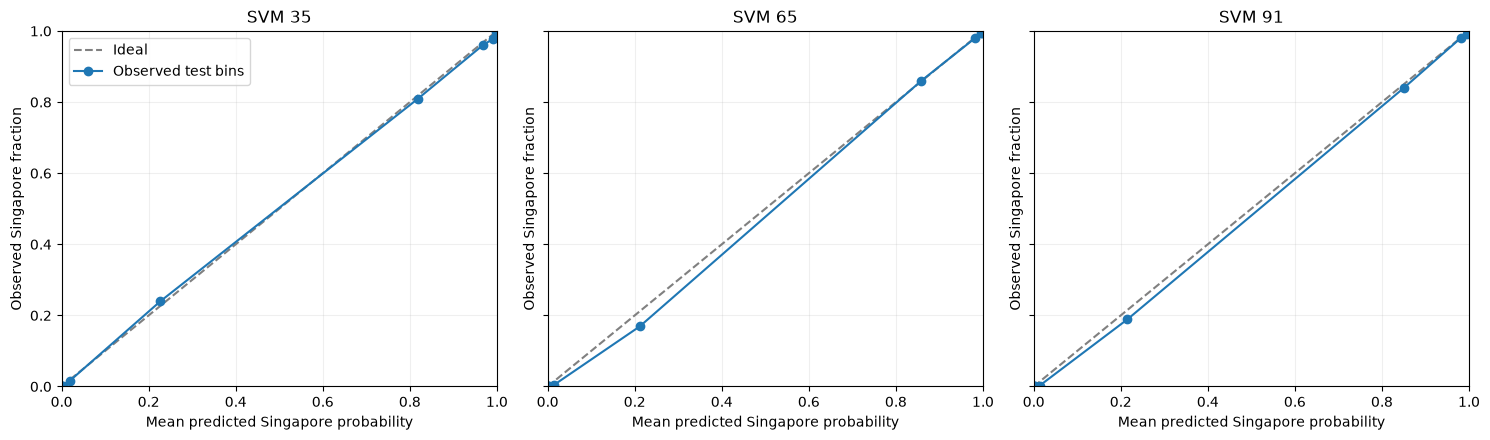

,feature_count,system,balanced_accuracy,singapore_recall,non_singapore_false_positive_rate,false_positive,false_negative,brier_score,log_loss
0,35,Original SVM,0.9460,0.9587,0.0667,150,93,NaN,NaN
1,35,Calibrated SVM at 0.50,0.9467,0.9538,0.0604,136,104,0.0387,0.1326
2,65,Original SVM,0.9624,0.9822,0.0573,129,40,NaN,NaN
3,65,Calibrated SVM at 0.50,0.9644,0.9751,0.0462,104,56,0.0275,0.0985
4,91,Original SVM,0.9611,0.9822,0.0600,135,40,NaN,NaN
5,91,Calibrated SVM at 0.50,0.9631,0.9742,0.0480,108,58,0.0280,0.0986


In [5]:
score_rows, outputs = [], []
fig, axes = plt.subplots(1, len(COUNTS), figsize=(5 * len(COUNTS), 4.5), sharex=True, sharey=True)
for count, axis in zip(COUNTS, axes):
    model = calibrated_models[count]
    source_features = features_by_count[count]
    result = predict_clip_probabilities(source_features[test_idx], model)
    result.insert(0, 'feature_count', count)
    result.insert(1, 'clip_id', clip_ids[test_idx])
    result.insert(2, 'speaker_group', groups[test_idx])
    result.insert(3, 'true_label', y[test_idx])
    raw_prediction = originals[count]['model'].predict(source_features[test_idx][:, originals[count]['columns']])
    result['original_svm_prediction'] = raw_prediction
    outputs.append(result)
    for name, prediction in [('Original SVM', raw_prediction),
                             ('Calibrated SVM at 0.50', result['predicted_class'].to_numpy())]:
        tn, fp, fn, tp = confusion_matrix(y[test_idx], prediction, labels=[0, 1]).ravel()
        calibrated = name.startswith('Calibrated')
        score_rows.append({'feature_count': count, 'system': name,
            'balanced_accuracy': balanced_accuracy_score(y[test_idx], prediction),
            'singapore_recall': tp / (tp + fn), 'non_singapore_false_positive_rate': fp / (tn + fp),
            'false_positive': int(fp), 'false_negative': int(fn),
            'brier_score': brier_score_loss(y[test_idx], result['p_singapore']) if calibrated else np.nan,
            'log_loss': log_loss(y[test_idx], result[['p_non_singapore', 'p_singapore']].to_numpy(), labels=[0, 1]) if calibrated else np.nan})
    fraction, mean_probability = calibration_curve(y[test_idx], result['p_singapore'], n_bins=10, strategy='quantile')
    axis.plot([0, 1], [0, 1], '--', color='gray', label='Ideal')
    axis.plot(mean_probability, fraction, 'o-', label='Observed test bins')
    axis.set(title=f'SVM {count}', xlabel='Mean predicted Singapore probability',
             ylabel='Observed Singapore fraction', xlim=(0, 1), ylim=(0, 1))
    axis.grid(alpha=.2)
axes[0].legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'test_probability_reliability.png', dpi=180, bbox_inches='tight')
plt.show()
test_summary = pd.DataFrame(score_rows)
test_predictions = pd.concat(outputs, ignore_index=True)
display(test_summary.round(4))
test_summary.to_csv(RESULTS_DIR / 'test_summary.csv', index=False)
test_predictions.to_csv(RESULTS_DIR / 'test_probability_predictions.csv', index=False)

## 5. Check saved models

Check that probabilities sum to one and reloaded models give the same classes.
At exactly 0.50, the helper chooses class 1; sklearn `predict()` chooses class 0.
Keep the feature-study model choice separate from these probability checks.

In [6]:
for count in COUNTS:
    model = joblib.load(RESULTS_DIR / f'svm_{count}_calibrated.joblib')
    source_features = features_by_count[count]
    rows = predict_clip_probabilities(source_features[test_idx], model)
    np.testing.assert_allclose(rows['p_singapore'] + rows['p_non_singapore'], 1.0)
    assert rows[['p_singapore', 'p_non_singapore']].ge(0).all().all()
    assert rows[['p_singapore', 'p_non_singapore']].le(1).all().all()
    direct = model.predict(source_features[test_idx][:, model.e1_probability_metadata_['columns']])
    not_tie = rows['p_singapore'].to_numpy() != 0.50
    np.testing.assert_array_equal(direct[not_tie], rows['predicted_class'].to_numpy()[not_tie])
    assert file_hash(STUDY_DIR / MODEL_PATHS[count]) == original_hashes[count]
    print(f'svm_{count}_calibrated.joblib: class/probability checks passed.')
print('Saved calibrated models, metadata, and test outputs:', RESULTS_DIR)

svm_35_calibrated.joblib: class/probability checks passed.


svm_65_calibrated.joblib: class/probability checks passed.


svm_91_calibrated.joblib: class/probability checks passed.
Saved calibrated models, metadata, and test outputs: /home/mh/E1_Feature_EngineeringV2/outputs/e1_feature_study_accent_30000/svm_calibrated_probability_testing
